# LeetCode #282: Expression Add Operators

https://leetcode.com/problems/expression-add-operators/

## Comparison of Approaches
| Approach | Time | Space |
|---|---|---|
| Backtracking ★ | O(4^n) | O(n) |

## Understanding the Methods
### Backtracking (Optimal)
Try all ways to split the string into numbers, and insert +, -, or * between them. Track the running total and the last operand (needed for multiplication precedence). When multiplying, undo the last addition/subtraction and apply the multiplication correctly. Skip numbers with leading zeros (except "0" itself). The branching factor is up to 4 (3 operators + different split lengths), giving O(4^n) time.

## Solutions

### C#

In [ ]:
public class Solution {
    public IList<string> AddOperators(string num, int target) {
        var result = new List<string>();
        Backtrack(num, target, 0, 0, 0, "", result);
        return result;
    }

    private void Backtrack(string num, int target, int idx, long eval, long multed, string path, List<string> result) {
        if (idx == num.Length) {
            if (eval == target) result.Add(path);
            return;
        }
        for (int i = idx; i < num.Length; i++) {
            if (i > idx && num[idx] == '0') break;
            long cur = long.Parse(num.Substring(idx, i - idx + 1));
            if (idx == 0) {
                Backtrack(num, target, i + 1, cur, cur, cur.ToString(), result);
            } else {
                Backtrack(num, target, i + 1, eval + cur, cur, path + "+" + cur, result);
                Backtrack(num, target, i + 1, eval - cur, -cur, path + "-" + cur, result);
                Backtrack(num, target, i + 1, eval - multed + multed * cur, multed * cur, path + "*" + cur, result);
            }
        }
    }
}

### Python

In [ ]:
class Solution:
    def addOperators(self, num: str, target: int) -> list[str]:
        result = []

        def backtrack(idx: int, eval_: int, multed: int, path: str) -> None:
            if idx == len(num):
                if eval_ == target:
                    result.append(path)
                return
            for i in range(idx, len(num)):
                if i > idx and num[idx] == '0':
                    break
                cur = int(num[idx:i + 1])
                if idx == 0:
                    backtrack(i + 1, cur, cur, str(cur))
                else:
                    backtrack(i + 1, eval_ + cur, cur, path + '+' + str(cur))
                    backtrack(i + 1, eval_ - cur, -cur, path + '-' + str(cur))
                    backtrack(i + 1, eval_ - multed + multed * cur, multed * cur, path + '*' + str(cur))

        backtrack(0, 0, 0, '')
        return result

### Go

In [ ]:
import (
    "fmt"
    "strconv"
)

func addOperators(num string, target int) []string {
    result := []string{}
    var backtrack func(idx int, eval, multed int64, path string)
    backtrack = func(idx int, eval, multed int64, path string) {
        if idx == len(num) {
            if eval == int64(target) {
                result = append(result, path)
            }
            return
        }
        for i := idx; i < len(num); i++ {
            if i > idx && num[idx] == '0' {
                break
            }
            cur, _ := strconv.ParseInt(num[idx:i+1], 10, 64)
            if idx == 0 {
                backtrack(i+1, cur, cur, fmt.Sprintf("%d", cur))
            } else {
                backtrack(i+1, eval+cur, cur, path+"+"+fmt.Sprintf("%d", cur))
                backtrack(i+1, eval-cur, -cur, path+"-"+fmt.Sprintf("%d", cur))
                backtrack(i+1, eval-multed+multed*cur, multed*cur, path+"*"+fmt.Sprintf("%d", cur))
            }
        }
    }
    backtrack(0, 0, 0, "")
    return result
}

### Rust

In [ ]:
impl Solution {
    pub fn add_operators(num: String, target: i32) -> Vec<String> {
        let mut result = Vec::new();
        let bytes = num.as_bytes();
        Self::backtrack(bytes, target as i64, 0, 0, 0, &mut String::new(), &mut result);
        result
    }

    fn backtrack(num: &[u8], target: i64, idx: usize, eval: i64, multed: i64, path: &mut String, result: &mut Vec<String>) {
        if idx == num.len() {
            if eval == target {
                result.push(path.clone());
            }
            return;
        }
        let mut cur: i64 = 0;
        let start_len = path.len();
        for i in idx..num.len() {
            if i > idx && num[idx] == b'0' { break; }
            cur = cur * 10 + (num[i] - b'0') as i64;
            let s = &cur.to_string();
            if idx == 0 {
                path.push_str(s);
                Self::backtrack(num, target, i + 1, cur, cur, path, result);
                path.truncate(start_len);
            } else {
                for (op, new_eval, new_mult) in [
                    ('+', eval + cur, cur),
                    ('-', eval - cur, -cur),
                    ('*', eval - multed + multed * cur, multed * cur),
                ] {
                    path.push(op);
                    path.push_str(s);
                    Self::backtrack(num, target, i + 1, new_eval, new_mult, path, result);
                    path.truncate(start_len);
                }
            }
        }
    }
}

## Example Scenarios

### 1. Common Case — Two Valid Expressions, num = "123"
**Input:** `num = "123", target = 6`
Reading each root&rarr;leaf path spells one expression. Both $1+2+3$ and $1 \times 2 \times 3$ evaluate to $6$.

### 2. Slightly Complex — Multiplication Precedence, num = "232"
**Input:** `num = "232", target = 8`
$2+3 \times 2 = 8$ and $2 \times 3+2 = 8$. The `*` branch must undo the last add/subtract and re-apply with precedence.

### 3. Edge Case: Time — Multi-Digit Splits & Leading Zeros, num = "105"
**Input:** `num = "105", target = 5`
A number can span digits: $10-5 = 5$ and $1 \times 0+5 = 5$. Any split that would start a number with `0` (like `"05"`) is pruned.

### 4. Edge Case: Space — Degenerate Zeros, num = "00"
**Input:** `num = "00", target = 0`
Each single `"0"` is a legal operand but `"00"` (concatenation) is not. Three expressions survive: $0+0,\; 0-0,\; 0 \times 0$.

### 5. Almost-Impossible but Plausible — No Solution, num = "3456237490"
**Input:** `num = "3456237490", target = 9191`
The search explores up to $O(4^n)$ operator/split combinations, yet none evaluates to $9191$, so the result is the empty list `[]`.


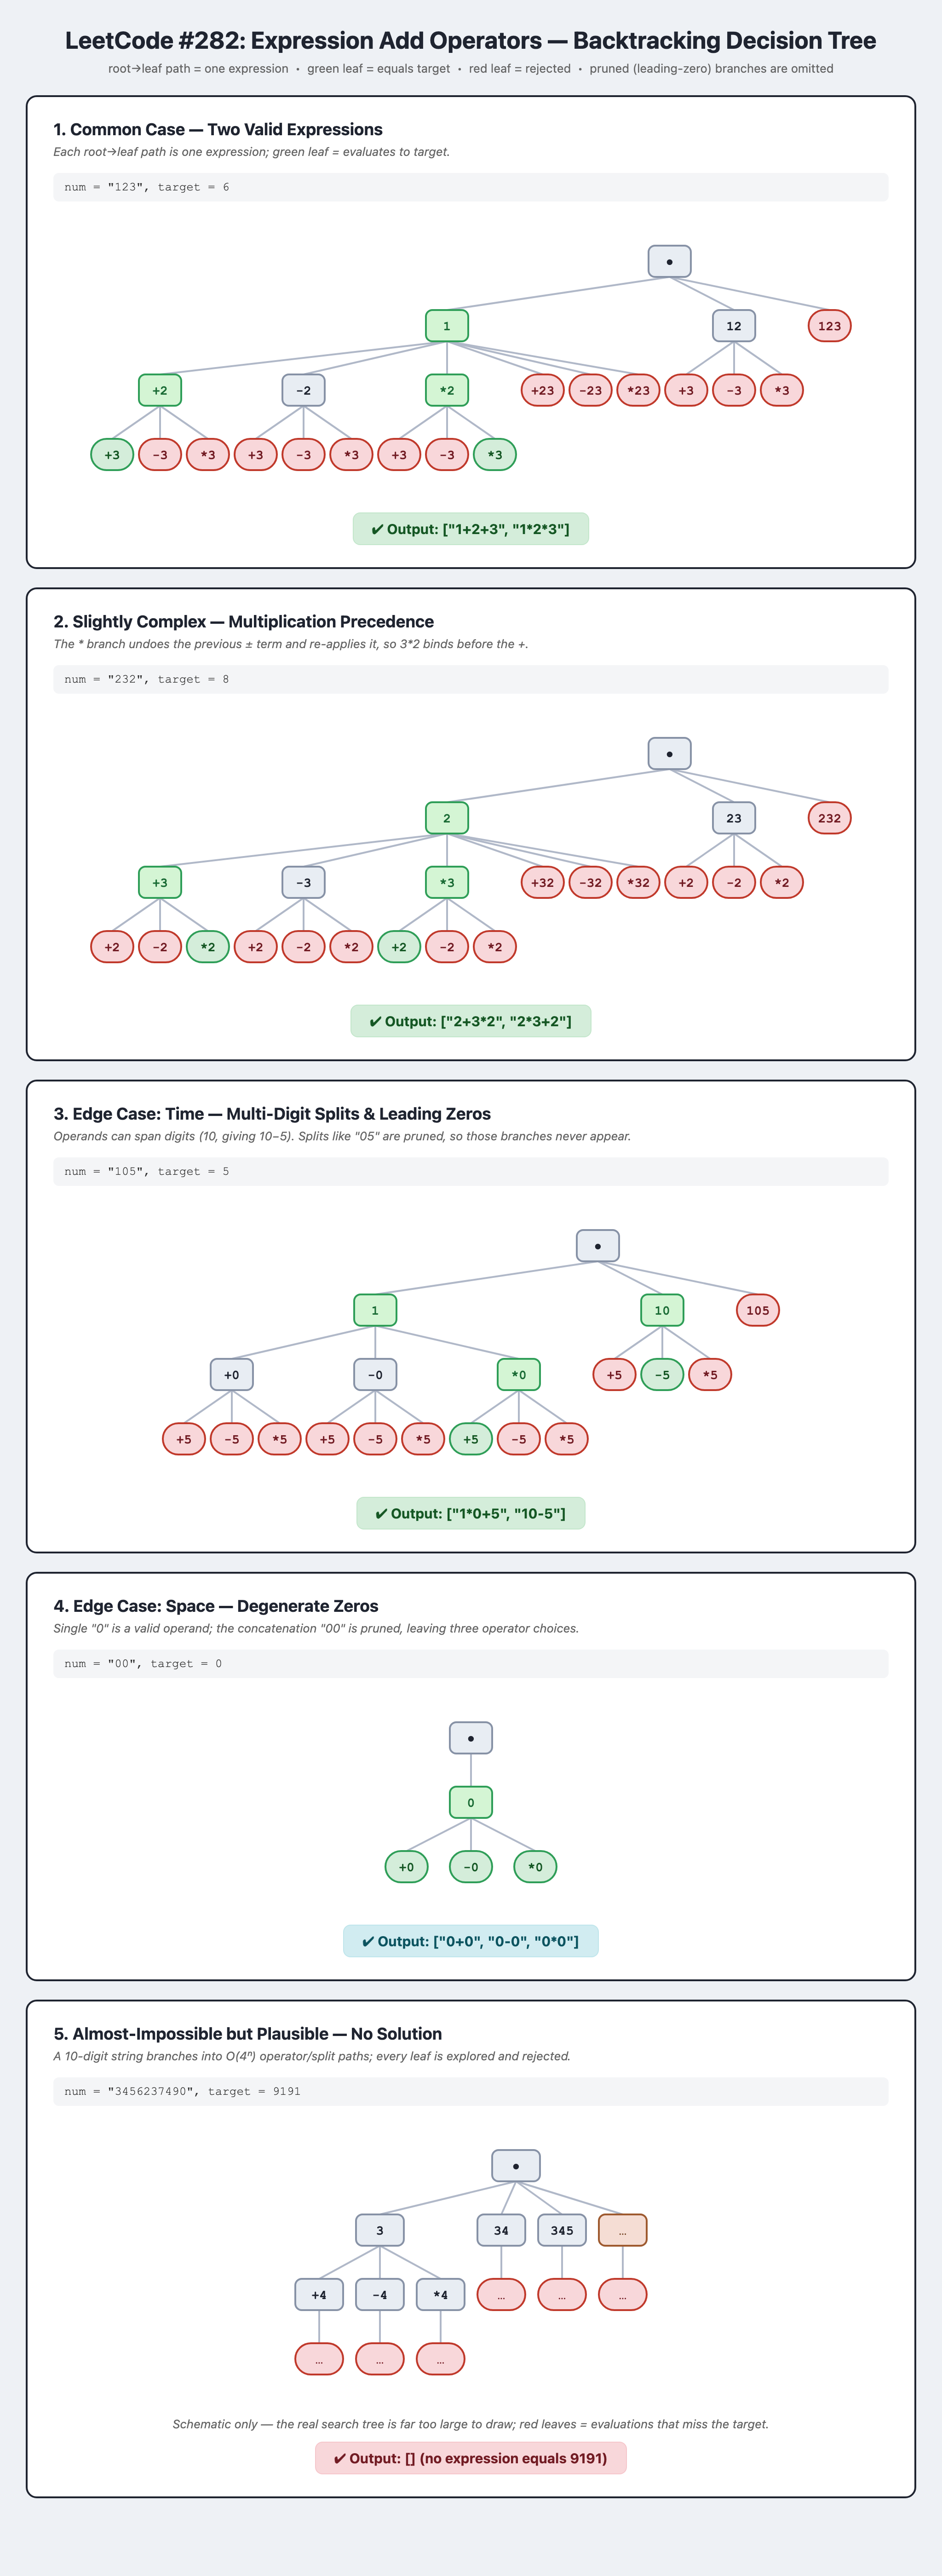